# The last bus of the evening

When does the last bus leave your street? For Greater Adelaide, Melbourne, Sydney and Brisbane, this notebook takes
the first and last bus to leave every stop on Wednesday 25 November 2026 and Sunday 29 November 2026 (from each
operator's published GTFS timetable) and each mesh block's residents (ABS Census 2021), and finds the share of
residents with a bus still to leave a stop within 400 m after each hour of the evening.

It reads only the files in `../data`. The script that read the timetables, `hours.mjs`, is beside it for reference: it
runs on Plotlay's own timetable reader, which is not in this repository.

**Read it carefully.** This is the timetable, not what ran. Buses only (other modes are in `numbers.json` for
comparison); school and on-demand services left out where the feed marks them. A stop counts when it is within 400 m of
a mesh block's middle in a straight line, not along streets. A terminus where buses only arrive is not a departure.

In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
DATA = '../data'
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
CITIES = ['adelaide', 'melbourne', 'sydney', 'brisbane']
N = json.load(open(f'{DATA}/numbers.json'))
mb = {c: pd.read_csv(f'{DATA}/mesh_blocks_{c}.csv', dtype={'mb_code': str}) for c in CITIES}
stops = {(c, d): pd.read_csv(f'{DATA}/stops_{c}_{d}.csv', dtype={'stop_id': str}) for c in CITIES for d in ('weekday', 'sunday')}
for c in CITIES: print(c, len(mb[c]), 'mesh blocks,', int(mb[c].people.sum()), 'residents,', len(stops[(c, 'weekday')]), 'stops with a bus on the weekday')

adelaide 15797 mesh blocks, 1386882 residents, 7181 stops with a bus on the weekday
melbourne 49586 mesh blocks, 4917585 residents, 19144 stops with a bus on the weekday
sydney 49319 mesh blocks, 5230011 residents, 26159 stops with a bus on the weekday
brisbane 24235 mesh blocks, 2526210 residents, 9544 stops with a bus on the weekday


## Each mesh block's last bus, worked out again from the stops

For every mesh block, the latest last departure among the stops within 400 m of its middle (in Australian Albers, EPSG:3577,
so the 400 m is in metres). It gives the `wd_last_bus_h` column the build wrote for all but a fraction of a per cent
of mesh blocks: the build measured 400 m on a local flat grid, so a stop right at 400 m can fall either side.

In [2]:
def last_near(c, day):
    m = gpd.GeoDataFrame(mb[c][['mb_code']], geometry=gpd.points_from_xy(mb[c].lng, mb[c].lat), crs=4326).to_crs(3577)
    s = stops[(c, day)]
    s = gpd.GeoDataFrame(s[['last_h']], geometry=gpd.points_from_xy(s.lng, s.lat), crs=4326).to_crs(3577)
    j = gpd.sjoin(m, s, predicate='dwithin', distance=400, how='left')
    return j.groupby(level=0).last_h.max().reindex(m.index)
for c in CITIES:
    again = last_near(c, 'weekday')
    have = mb[c].wd_last_bus_h
    same = np.isclose(again.fillna(-1), have.fillna(-1), atol=0.01)
    print(f'{c}: {same.mean():.4%} of mesh blocks agree')

adelaide: 99.8544% of mesh blocks agree
melbourne: 99.3486% of mesh blocks agree


sydney: 99.5357% of mesh blocks agree
brisbane: 99.1129% of mesh blocks agree


## Residents with a bus still to come

A resident has a bus still to come after a time when the latest last bus within 400 m leaves at or after it. A resident
with no stop within 400 m (or none with a bus that day) has none.

In [3]:
rows = []
for c in CITIES:
    m = mb[c]; tot = m.people.sum()
    for day, col in (('weekday', 'wd_last_bus_h'), ('sunday', 'su_last_bus_h')):
        last = m[col].fillna(0)
        r = {'city': c.title(), 'day': day, 'no stop within 400 m (%)': round(100 * m.people[m.stops_400m == 0].sum() / tot, 1)}
        for h in (19, 21, 22, 23, 24): r[f'after {h % 24:02d}:00 (%)'] = round(100 * m.people[last >= h].sum() / tot, 1)
        rows.append(r)
t = pd.DataFrame(rows)
for c in CITIES:
    a = t[(t.city == c.title()) & (t.day == 'weekday')].iloc[0]
    assert a['after 21:00 (%)'] == N['cities'][c.title()]['bus_after_21_pct'], c
t

,city,day,no stop within 400 m (%),after 19:00 (%),after 21:00 (%),after 22:00 (%),after 23:00 (%),after 00:00 (%)
0,Adelaide,weekday,13.9,80.0,73.6,71.3,62.2,33.0
1,Adelaide,sunday,13.9,72.7,71.0,69.5,62.1,26.0
2,Melbourne,weekday,19.0,78.2,73.0,47.9,26.4,18.5
3,Melbourne,sunday,19.0,74.2,69.0,31.6,11.6,3.3
4,Sydney,weekday,7.0,87.5,80.7,71.9,61.7,42.3
5,Sydney,sunday,7.0,77.1,66.9,60.2,45.1,31.8
6,Brisbane,weekday,23.6,62.3,43.1,36.1,31.5,12.8
7,Brisbane,sunday,23.6,34.7,26.5,18.3,15.1,3.8


## The hour in Melbourne

Between 9 and 10 pm, the latest bus within 400 m leaves for about a quarter of Greater Melbourne's residents.

In [4]:
for c in CITIES:
    m = mb[c]; last = m.wd_last_bus_h.fillna(0)
    n = m.people[(last >= 21) & (last < 22)].sum()
    print(f'{c.title():10s} last bus between 9 and 10 pm: {n:>10,.0f} residents ({100 * n / m.people.sum():.1f}%)')

Adelaide   last bus between 9 and 10 pm:     32,476 residents (2.3%)
Melbourne  last bus between 9 and 10 pm:  1,233,765 residents (25.1%)
Sydney     last bus between 9 and 10 pm:    459,876 residents (8.8%)
Brisbane   last bus between 9 and 10 pm:    177,022 residents (7.0%)


## The evening curve

Every 10 minutes from 5 pm to 2 am, the share of each city's residents with a bus still to come.

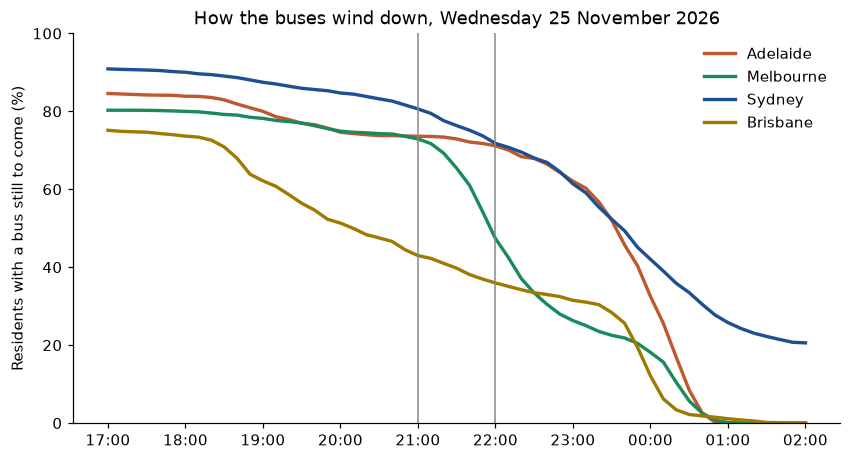

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colours = {'adelaide': '#c0582f', 'melbourne': '#1b8a5a', 'sydney': '#1d4f91', 'brisbane': '#a07a00'}
ts = np.arange(17, 26.01, 1 / 6)
for c in CITIES:
    m = mb[c]; last = m.wd_last_bus_h.fillna(0).to_numpy(); p = m.people.to_numpy(); tot = p.sum()
    ax.plot(ts, [100 * p[last >= t].sum() / tot for t in ts], color=colours[c], lw=2.2, label=c.title())
ax.set_xticks(range(17, 27), [f'{h % 24:02d}:00' for h in range(17, 27)]); ax.set_ylim(0, 100)
ax.set_ylabel('Residents with a bus still to come (%)'); ax.axvline(21, color='#888', lw=1); ax.axvline(22, color='#888', lw=1)
ax.legend(frameon=False); ax.set_title('How the buses wind down, Wednesday 25 November 2026')
plt.show()

## The suburbs

`suburbs.csv` adds the mesh blocks up by ABS suburb and locality (each mesh block in the suburb its middle falls in).
The big suburbs (15,000 residents or more, nearly all of them within 400 m of a stop) with the fewest residents with a
bus after 9 pm:

In [6]:
sub = pd.read_csv(f'{DATA}/suburbs.csv', dtype={'sal_code': str})
big = sub[(sub.residents >= 15000) & (sub.stop_400m_pct >= 85)]
big.sort_values('wd_bus_after_21_pct')[['city', 'suburb', 'residents', 'stop_400m_pct', 'wd_bus_after_21_pct', 'wd_bus_after_22_pct', 'su_bus_after_21_pct']].head(10)

,city,suburb,residents,stop_400m_pct,wd_bus_after_21_pct,wd_bus_after_22_pct,su_bus_after_21_pct
981,Brisbane,Rochedale South,15232,93.7,0.0,0.0,0.0
660,Brisbane,Deception Bay,19619,87.8,1.8,0.0,0.0
597,Brisbane,Capalaba,17991,89.4,18.1,14.6,0.0
499,Brisbane,Alexandra Hills,16458,96.9,27.3,23.3,0.0
751,Brisbane,Inala,15516,98.9,28.0,28.0,28.0
625,Brisbane,Cleveland,15832,86.9,30.8,30.8,3.4
769,Brisbane,Kallangur,21715,85.4,33.4,17.1,0.0
1725,Sydney,Auburn,39310,99.7,33.8,32.9,32.9
1452,Melbourne,Malvern East,22283,87.2,36.7,24.3,36.7
1076,Brisbane,Victoria Point,15158,91.6,44.0,11.5,0.0


## Greater Melbourne after 9 pm and after 10 pm

Suburbs with fewer than 200 residents a km² in grey, as in Plotlay.

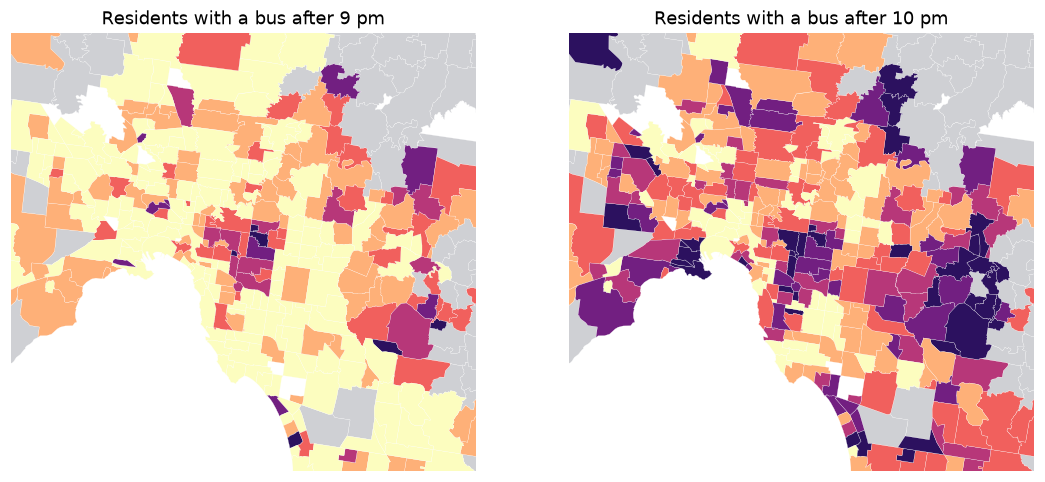

In [7]:
g = gpd.read_file(f'{DATA}/suburbs.geojson')
g = g[g.city == 'Melbourne'].merge(sub[['sal_code', 'sparse', 'wd_bus_after_22_pct']], on='sal_code', suffixes=('', '_t'))
cols = ['#2c115f', '#721f81', '#b73779', '#f1605d', '#feb078', '#fcfdbf']
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, col, ttl in ((axs[0], 'wd_bus_after_21_pct', 'After 9 pm'), (axs[1], 'wd_bus_after_22_pct', 'After 10 pm')):
    dense = g[g['sparse'].isna()]
    g[g['sparse'].notna()].plot(ax=ax, color='#cfd0d4', edgecolor='white', linewidth=0.15)
    dense.plot(column=col, cmap=ListedColormap(cols), norm=BoundaryNorm([-1, 0.01, 20, 40, 60, 80, 101], 6), ax=ax, edgecolor='white', linewidth=0.15)
    ax.set_xlim(144.7, 145.4); ax.set_ylim(-38.1, -37.58); ax.set_axis_off(); ax.set_title(f'Residents with a bus {ttl.lower()}')
plt.show()

Sources: GTFS timetables of Adelaide Metro (Department for Infrastructure and Transport, South Australia), Transport
Victoria, Transport for NSW and Translink (Department of Transport and Main Roads, Queensland), all CC BY 4.0. Census
2021 mesh block counts, Mesh Blocks and Suburbs and Localities 2021 (ASGS Edition 3), Australian Bureau of Statistics,
CC BY 4.0. Made with [Plotlay](https://www.getplotlay.com).